# Week 6 Homework: Your Answers vs. Your Vibe-Coded Dashboard

**Week 4 dashboard link:** https://hmin6-movielens-dashboard.streamlit.app/

---

Two weeks ago you vibe-coded a MovieLens dashboard before you had the tools to judge it. Since then you've had the stats lecture (Week 5) and this week's EDA lecture. Now you do it the real way: answer the same 4 questions yourself, by hand, then audit the dashboard against your own work.

**Ground rules**

- 🚫 **No AI for code or answers in Parts 1 and 2.** Lecture notebooks, pandas/seaborn docs, Google, and Stack Overflow are all fair game. Write Part 3 in your own words too.
- 🔒 **Lock in before you peek.** Finish Parts 1 and 2 (answers written down) *before* you open your dashboard. If you look first, you'll anchor on its numbers and the comparison is worthless.
- 🔢 **Show your numbers.** Every answer needs actual values (counts, averages, titles), not just a vibe.
- ✏️ Written answers go in markdown cells (double-click to edit, Shift+Enter to render). Most are 2 to 4 sentences. Short and specific beats long and vague.

Note on AI use: the ground rules above say no AI for Parts 1 and 2 and ask for Part 3 in my own words. My instructor updated the permission for this assignment to allow AI assistance, including Parts 1 and 2. I used an AI coding assistant (Claude Code) to help write the analysis code and draft the written answers, and every number comes from running the code in this notebook. The reflections in 3.1 and 3.5 describe my own Week 4 process, checked against my build transcript, and AI assistance was also used in drafting them.

## The data

`movie_ratings.csv` has one row per rating: 100,000 ratings from 943 users on 1,682 movies.

- `user_id`, `movie_id`: who rated, which movie
- `rating`: 1 to 5 stars
- `timestamp`, `rating_year`: when the rating was given
- `age`, `gender`, `occupation`, `zip_code`: the rater
- `title`: movie title, with release year in parentheses
- `year`, `decade`: the movie's release year and decade
- `genres`: all of the movie's genres in one string, separated by the pipe character (a movie can have several)

## Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Works whether this notebook sits in the week folder or inside exercise/
data_path = next(p for p in ["data/movie_ratings.csv", "../data/movie_ratings.csv"] if Path(p).exists())
df = pd.read_csv(data_path)
df.head()

,user_id,movie_id,rating,timestamp,age,gender,occupation,zip_code,title,year,decade,genres,rating_year
0,196,242,3,1997-12-04 15:55:49,49,M,writer,55105,Kolya (1996),1996.0,1990.0,Comedy,1997
1,186,302,3,1998-04-04 19:22:22,39,F,executive,00000,L.A. Confidential (1997),1997.0,1990.0,Crime|Film-Noir|Mystery|Thriller,1998
2,22,377,1,1997-11-07 07:18:36,25,M,writer,40206,Heavyweights (1994),1994.0,1990.0,Children|Comedy,1997
3,244,51,2,1997-11-27 05:02:03,28,M,technician,80525,Legends of the Fall (1994),1994.0,1990.0,Drama|Romance|War|Western,1997
4,166,346,1,1998-02-02 05:33:16,47,M,educator,55113,Jackie Brown (1997),1997.0,1990.0,Crime|Drama,1998


---
# Part 1: Methodology

## 1.1 Know your data first

Before answering anything, check what you're working with: shape, column types, missing values, duplicate rows, and the range of the numeric columns.

In [2]:
# Your data checks here
print(df.shape)
df.info()

(100000, 13)
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 13 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   user_id      100000 non-null  int64  
 1   movie_id     100000 non-null  int64  
 2   rating       100000 non-null  int64  
 3   timestamp    100000 non-null  str    
 4   age          100000 non-null  int64  
 5   gender       100000 non-null  str    
 6   occupation   100000 non-null  str    
 7   zip_code     100000 non-null  str    
 8   title        100000 non-null  str    
 9   year         99970 non-null   float64
 10  decade       99970 non-null   float64
 11  genres       100000 non-null  str    
 12  rating_year  100000 non-null  int64  
dtypes: float64(2), int64(5), str(6)
memory usage: 9.9 MB


In [3]:
df.isnull().sum()

user_id         0
movie_id        0
rating          0
timestamp       0
age             0
gender          0
occupation      0
zip_code        0
title           0
year           30
decade         30
genres          0
rating_year     0
dtype: int64

In [4]:
print('Duplicate rows:', df.duplicated().sum())
print('Same user rating the same movie twice:', df.duplicated(subset=['user_id', 'movie_id']).sum())
df.describe()

Duplicate rows: 0
Same user rating the same movie twice: 0


,user_id,movie_id,rating,age,year,decade,rating_year
count,100000.00000,100000.000000,100000.000000,100000.000000,99970.000000,99970.000000,100000.000000
mean,462.48475,425.530130,3.529860,32.969850,1987.748224,1982.780134,1997.471010
std,266.61442,330.798356,1.125674,11.562623,14.140014,13.820687,0.499161
min,1.00000,1.000000,1.000000,7.000000,1922.000000,1920.000000,1997.000000
25%,254.00000,175.000000,3.000000,24.000000,1986.000000,1980.000000,1997.000000
50%,447.00000,322.000000,4.000000,30.000000,1994.000000,1990.000000,1997.000000
75%,682.00000,631.000000,4.000000,40.000000,1996.000000,1990.000000,1998.000000
max,943.00000,1682.000000,5.000000,73.000000,1998.000000,1990.000000,1998.000000


In [5]:
df.nunique()

user_id          943
movie_id        1682
rating             5
timestamp      49282
age               61
gender             2
occupation        21
zip_code         795
title           1664
year              71
decade             8
genres           216
rating_year        2
dtype: int64

In [6]:
df[df['year'].isna()].groupby(['movie_id', 'title'])['rating'].count()

movie_id  title                                                        
267       unknown                                                           9
1128      Heidi Fleiss: Hollywood Madam (1995)                             13
1201      Marlene Dietrich: Shadow and Light (1996)                         1
1412      Land Before Time III: The Time of the Great Giving (1995) (V)     6
1635      Two Friends (1986)                                                1
Name: rating, dtype: int64

In [7]:
df[df['genres'].str.contains('unknown')].groupby(['movie_id', 'title'])['rating'].count()

movie_id  title              
267       unknown                9
1373      Good Morning (1971)    1
Name: rating, dtype: int64

In [8]:
ids_per_title = df.groupby('title')['movie_id'].nunique()
ids_per_title[ids_per_title > 1]

title
Body Snatchers (1993)             2
Butcher Boy, The (1998)           2
Chairman of the Board (1998)      2
Chasing Amy (1997)                2
Deceiver (1997)                   2
Designated Mourner, The (1997)    2
Desperate Measures (1998)         2
Fly Away Home (1996)              2
Hugo Pool (1997)                  2
Hurricane Streets (1998)          2
Ice Storm, The (1997)             2
Kull the Conqueror (1997)         2
Money Talks (1997)                2
Nightwatch (1997)                 2
Sliding Doors (1998)              2
Substance of Fire, The (1996)     2
That Darn Cat! (1997)             2
Ulee's Gold (1997)                2
Name: movie_id, dtype: int64

In [9]:
print('Ratings given from', df['timestamp'].min(), 'to', df['timestamp'].max())
df.groupby('user_id')['rating'].count().describe()

Ratings given from 1997-09-20 03:05:10 to 1998-04-22 23:10:38


count    943.000000
mean     106.044539
std      100.931743
min       20.000000
25%       33.000000
50%       65.000000
75%      148.000000
max      737.000000
Name: rating, dtype: float64

**✏️ Data notes:** The file has 100,000 ratings and 13 columns from 943 users on 1,682 movies. There are no duplicate rows, and no user rated the same movie twice. Ratings are whole numbers from 1 to 5 (mean 3.53), age runs from 7 to 73, and every user has at least 20 ratings.

- Missing release year: only `year` and `decade` have missing values, 30 ratings across 5 movies. I kept these rows for Q1, Q2 and Q4 and dropped them only for Q3. Four of the five titles have a year in parentheses (21 ratings), but adding them to years that already have 1,552 to 18,744 ratings wouldn't visibly change any yearly average.
- Genre `unknown`: 2 movies (10 ratings) have this placeholder genre. I kept the movies but left `unknown` out of the genre results.
- 18 titles appear under two different `movie_id`s, for example Chasing Amy (1997). I grouped by `movie_id` and checked in Q4 that grouping by title gives the same top 5.
- `rating_year` only has two values, 1997 and 1998. All ratings were given between September 1997 and April 1998, so the data is a snapshot, not a history.

## 1.2 Decide before you chart

In Week 4 the questions were ambiguous on purpose. This is where *you* commit to an interpretation. Fill it in now, and update it if you change your mind while working (just say so).

**Q1 Genre breakdown**
- What you have to decide: What am I counting, ratings or movies? How do I handle movies that have several genres?
- My choice: Distinct movies per genre. A movie with several genres counts once in each of its genres. I report each genre's share of the 1,682 movies and show the number of ratings for context, and I leave out `unknown`.
- Why: The question asks about the movies that were rated, so the unit is the movie. Counting ratings would mostly measure popularity. Since a movie has 1.72 genres on average, the percentages add up to about 172%.

**Q2 Genre satisfaction**
- What you have to decide: "Average rating" of what? How do I treat genres that have very little data?
- My choice: The mean of all individual ratings in each genre, shown with the number of ratings, the number of movies and a rough 95% interval. I drop `unknown` (10 ratings). Every other genre has at least 758 ratings, so I keep them all, but I note the ones based on fewer than 30 movies (Fantasy with 22, Film-Noir with 24 and Western with 27).
- Why: This answers which genres raters rate highest. The counts and intervals show that an average from 1,352 ratings of 22 movies is weaker evidence than one from 39,895 ratings of 725 movies.

**Q3 Ratings over time**
- What you have to decide: Is every year backed by the same amount of data? What do I do with movies that have no release year?
- My choice: The mean rating per release year, with the number of ratings per year shown underneath and years with fewer than 50 ratings marked. I drop the 30 ratings with no release year from this question only.
- Why: The years are not equally backed. About 69% of the ratings are for 1990s movies, while 1926 has only 2 ratings. A missing year can't be placed on the timeline, and 30 out of 100,000 ratings can't change the trend.

**Q4 Best movies**
- What you have to decide: What is a movie's rating (the mean of what)? Is "at least 50" ≥ or >? What if there's a tie?
- My choice: A movie's rating is the mean of its individual ratings, grouped by `movie_id`. "At least 50" means ≥ 50 (and ≥ 150). Ties are broken by number of ratings, then by title.
- Why: "At least" includes the boundary. When two movies have the same average, the one with more ratings has more evidence behind it.

---
# Part 2: Results (by hand, no AI)

Answer each question with a chart or table **and** a written answer with real numbers. Pick the chart type yourself and be ready to defend it in Part 3. Add as many code cells as you need.

## Q1. Genre breakdown

**What's the distribution of genres among the movies that were rated?**

<details>
<summary>Stuck on movies with several genres? Hint</summary>

`genres` is one string like `Crime|Film-Noir|Mystery|Thriller`. To get one row per genre:

```python
genre_df = df.assign(genre=df['genres'].str.split('|')).explode('genre')
```

Heads up: after this, a movie with 3 genres takes up 3 rows. Think about what that does to anything you count or average. Exploding is fine for "how often does a genre show up", but be careful calling the result "market share" (the percentages add up to more than 100%).
</details>

In [10]:
# Q1: your code here
sns.set()

genre_df = df.assign(genre=df['genres'].str.split('|')).explode('genre')
total_movies = df['movie_id'].nunique()

q1 = pd.DataFrame({
    'movies': genre_df.groupby('genre')['movie_id'].nunique(),
    'ratings': genre_df.groupby('genre')['rating'].count(),
}).sort_values('movies', ascending=False)
q1['pct_of_movies'] = (q1['movies'] / total_movies * 100).round(1)
q1['pct_of_ratings'] = (q1['ratings'] / len(df) * 100).round(1)

print('Genres per movie on average:', round(q1['movies'].sum() / total_movies, 2))
q1

Genres per movie on average: 1.72


,movies,ratings,pct_of_movies,pct_of_ratings
genre,,,,
Drama,725,39895,43.1,39.9
Comedy,505,29832,30.0,29.8
Action,251,25589,14.9,25.6
Thriller,251,21872,14.9,21.9
Romance,247,19461,14.7,19.5
Adventure,135,13753,8.0,13.8
Children,122,7182,7.3,7.2
Crime,109,8055,6.5,8.1
Sci-Fi,101,12730,6.0,12.7


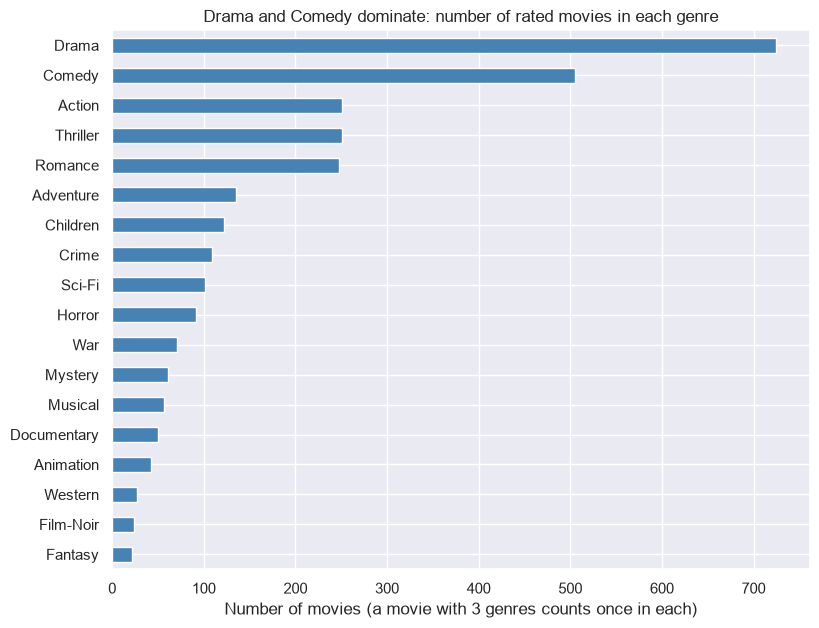

In [11]:
q1_plot = q1[q1.index != 'unknown']
ax = q1_plot['movies'].sort_values().plot(kind='barh', figsize=(9, 7), color='steelblue')
ax.set(title='Drama and Comedy dominate: number of rated movies in each genre',
       xlabel='Number of movies (a movie with 3 genres counts once in each)', ylabel='')
plt.show()

**✏️ My answer (with numbers):** I counted distinct movies per genre, with each movie counted once in every genre it belongs to. Drama is the largest genre with 725 of 1,682 movies (43.1%), followed by Comedy with 505 (30.0%). Action and Thriller (251 each, 14.9%) and Romance (247, 14.7%) come next. The smallest are Fantasy (22 movies, 1.3%), Film-Noir (24) and Western (27). Counting ratings would give a different picture: Action is 14.9% of the movies but 25.6% of the ratings, and Documentary is 3.0% of the movies but only 0.8% of the ratings.

## Q2. Genre satisfaction

**Which genres have the highest average rating? Which have the lowest?**

Show how much data is behind each average (for example, the count next to it). An average of 10 ratings and an average of 10,000 ratings are not the same kind of evidence.

In [12]:
# Q2: your code here
import numpy as np

rated = genre_df[genre_df['genre'] != 'unknown']
q2 = rated.groupby('genre')['rating'].agg(['mean', 'std', 'count'])
q2['movies'] = rated.groupby('genre')['movie_id'].nunique()
q2['ci_low'] = q2['mean'] - 1.96 * q2['std'] / np.sqrt(q2['count'])
q2['ci_high'] = q2['mean'] + 1.96 * q2['std'] / np.sqrt(q2['count'])
q2 = q2.sort_values('mean', ascending=False)
q2.round(3)

,mean,std,count,movies,ci_low,ci_high
genre,,,,,,
Film-Noir,3.922,0.993,1733,24,3.875,3.968
War,3.816,1.080,9398,71,3.794,3.838
Drama,3.687,1.079,39895,725,3.677,3.698
Documentary,3.673,1.180,758,50,3.589,3.757
Mystery,3.638,1.091,5245,61,3.609,3.668
Crime,3.632,1.113,8055,109,3.608,3.657
Romance,3.622,1.096,19461,247,3.606,3.637
Western,3.613,1.042,1854,27,3.566,3.661
Animation,3.577,1.097,3605,42,3.541,3.612


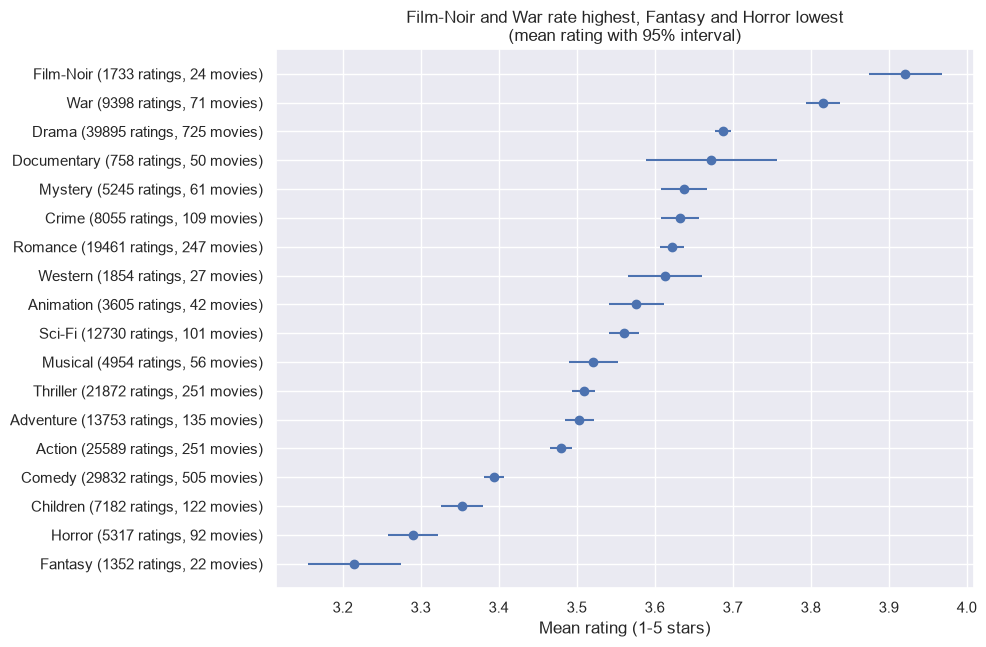

In [13]:
plot_df = q2.sort_values('mean').reset_index()
plot_df['label'] = (plot_df['genre'] + ' (' + plot_df['count'].astype(str) + ' ratings, '
                    + plot_df['movies'].astype(str) + ' movies)')

fig, ax = plt.subplots(figsize=(9, 7))
ax.errorbar(plot_df['mean'], plot_df['label'], xerr=plot_df['mean'] - plot_df['ci_low'], fmt='o')
ax.set(title='Film-Noir and War rate highest, Fantasy and Horror lowest\n(mean rating with 95% interval)',
       xlabel='Mean rating (1-5 stars)', ylabel='')
plt.show()

**✏️ My answer (with numbers):** The highest-rated genres are Film-Noir at 3.92 (1,733 ratings, 24 movies), War at 3.82 (9,398 ratings, 71 movies) and Drama at 3.69 (39,895 ratings, 725 movies). The lowest are Fantasy at 3.22 (1,352 ratings, 22 movies), Horror at 3.29 (5,317 ratings, 92 movies) and Children at 3.35 (7,182 ratings, 122 movies). All genres fall between 3.22 and 3.92, around the overall mean of 3.53. Film-Noir has the highest observed mean, and its rough interval (3.87 to 3.97) doesn't overlap War's (3.79 to 3.84), but these intervals treat every rating as independent even though the same movies and users appear in many ratings, so they are likely too narrow. Fantasy's interval (3.16 to 3.27) slightly overlaps Horror's (3.26 to 3.32), so the bottom spot is less certain.

## Q3. Ratings over time

**How has the mean rating changed across movie release years?**

Show how many ratings each year is based on, alongside the trend.

In [14]:
# Q3: your code here
dated = df.dropna(subset=['year'])
q3 = dated.groupby('year')['rating'].agg(['mean', 'count'])
q3['movies'] = dated.groupby('year')['movie_id'].nunique()
thin = q3[q3['count'] < 50]

print('Ratings with no release year:', len(df) - len(dated))
print('Share of ratings for 1990s movies:', round((dated['year'] >= 1990).mean(), 3))
thin

Ratings with no release year: 30
Share of ratings for 1990s movies: 0.695


,mean,count,movies
year,,,
1926.0,3.000000,2,1
1930.0,3.777778,18,1
1931.0,4.000000,44,1
1932.0,3.833333,12,1
1936.0,3.769231,39,2
1943.0,3.750000,24,4


In [15]:
by_decade = dated.groupby('decade')['rating'].agg(['mean', 'count'])
by_decade['movies'] = dated.groupby('decade')['movie_id'].nunique()
by_decade.round(2)

,mean,count,movies
decade,,,
1920.0,3.54,56,2
1930.0,3.93,1496,29
1940.0,4.01,2249,45
1950.0,3.94,3527,57
1960.0,3.88,3909,46
1970.0,3.87,6448,55
1980.0,3.77,12833,109
1990.0,3.39,69452,1334


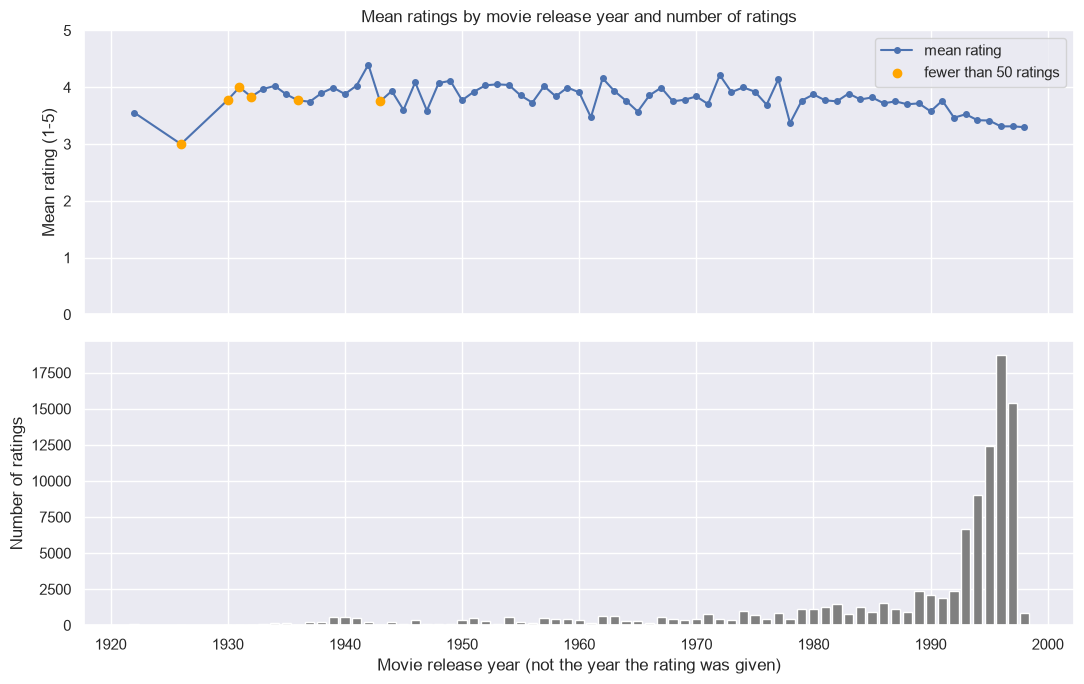

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(q3.index, q3['mean'], marker='o', markersize=4, label='mean rating')
axes[0].scatter(thin.index, thin['mean'], color='orange', zorder=3, label='fewer than 50 ratings')
axes[0].set(title='Mean ratings by movie release year and number of ratings',
            ylabel='Mean rating (1-5)')
axes[0].set_ylim(0, 5)
axes[0].legend()
axes[1].bar(q3.index, q3['count'], color='gray')
axes[1].set(xlabel='Movie release year (not the year the rating was given)', ylabel='Number of ratings')
plt.tight_layout()
plt.show()

**✏️ My answer (with numbers):** Average ratings go down as release years get more recent. By decade, the mean is 3.93 for the 1930s, 4.01 for the 1940s, 3.94 for the 1950s, 3.88 for the 1960s, 3.87 for the 1970s, 3.77 for the 1980s and 3.39 for the 1990s. Within the 1990s it falls from 3.58 in 1990 to about 3.30 in 1996 to 1998. The trend isn't equally reliable across the timeline. 1990s movies make up 69.5% of all ratings (1996 alone has 18,744), while 6 years have fewer than 50 ratings and 1926 has just 2. Every year before 1981 is based on 9 movies or fewer, which is why the early part of the line jumps around; 1942 averages 4.40 from only 2 movies.

## Q4. Best movies, with a floor

**What are the 5 best-rated movies that have at least 50 ratings? What changes if you raise the floor to 150?**

In [17]:
# Q4: your code here
per_movie = df.groupby(['movie_id', 'title'])['rating'].agg(['mean', 'count']).reset_index()

def top_movies(table, floor):
    eligible = table[table['count'] >= floor]
    return eligible.sort_values(['mean', 'count', 'title'], ascending=[False, False, True]).head(5)

top50 = top_movies(per_movie, 50)
top150 = top_movies(per_movie, 150)
print('Movies with at least 50 ratings:', (per_movie['count'] >= 50).sum())
print('Movies with at least 150 ratings:', (per_movie['count'] >= 150).sum())
top50.round(3)

Movies with at least 50 ratings: 603
Movies with at least 150 ratings: 203


,movie_id,title,mean,count
407,408,"Close Shave, A (1995)",4.491,112
317,318,Schindler's List (1993),4.466,298
168,169,"Wrong Trousers, The (1993)",4.466,118
482,483,Casablanca (1942),4.457,243
113,114,Wallace & Gromit: The Best of Aardman Animatio...,4.448,67


In [18]:
top150.round(3)

,movie_id,title,mean,count
317,318,Schindler's List (1993),4.466,298
482,483,Casablanca (1942),4.457,243
63,64,"Shawshank Redemption, The (1994)",4.445,283
602,603,Rear Window (1954),4.388,209
11,12,"Usual Suspects, The (1995)",4.386,267


In [19]:
ranked = per_movie[per_movie['count'] >= 50].sort_values(['mean', 'count', 'title'], ascending=[False, False, True])
ranked = ranked.reset_index(drop=True)
ranked['rank_at_50'] = ranked.index + 1
ranked['in_top5_at_150'] = ranked['title'].isin(top150['title'])
ranked[ranked['title'].isin(top50['title']) | ranked['in_top5_at_150']].round(3)

,movie_id,title,mean,count,rank_at_50,in_top5_at_150
0,408,"Close Shave, A (1995)",4.491,112,1,False
1,318,Schindler's List (1993),4.466,298,2,True
2,169,"Wrong Trousers, The (1993)",4.466,118,3,False
3,483,Casablanca (1942),4.457,243,4,True
4,114,Wallace & Gromit: The Best of Aardman Animatio...,4.448,67,5,False
5,64,"Shawshank Redemption, The (1994)",4.445,283,6,True
6,603,Rear Window (1954),4.388,209,7,True
7,12,"Usual Suspects, The (1995)",4.386,267,8,True


In [20]:
strict50 = per_movie[per_movie['count'] > 50].sort_values(['mean', 'count'], ascending=False).head(5)
strict150 = per_movie[per_movie['count'] > 150].sort_values(['mean', 'count'], ascending=False).head(5)
by_title = df.groupby('title')['rating'].agg(['mean', 'count']).reset_index()

print('> instead of >= gives the same lists:',
      list(strict50['title']) == list(top50['title']) and list(strict150['title']) == list(top150['title']))
print('Grouping by title gives the same lists:',
      list(top_movies(by_title, 50)['title']) == list(top50['title'])
      and list(top_movies(by_title, 150)['title']) == list(top150['title']))
print('Ties in the top 5:', top50['mean'].duplicated().any() or top150['mean'].duplicated().any())
print('Movies with a perfect 5.0:', (per_movie['mean'] == 5).sum())
print('Movies with only 1 rating:', (per_movie['count'] == 1).sum())
top_movies(per_movie, 1)

> instead of >= gives the same lists: True
Grouping by title gives the same lists: True
Ties in the top 5: False
Movies with a perfect 5.0: 10
Movies with only 1 rating: 141


,movie_id,title,mean,count
1188,1189,Prefontaine (1997),5.0,3
1292,1293,Star Kid (1997),5.0,3
1466,1467,"Saint of Fort Washington, The (1993)",5.0,2
1499,1500,Santa with Muscles (1996),5.0,2
1535,1536,Aiqing wansui (1994),5.0,1


**✏️ My answer (with numbers):** With a floor of at least 50 ratings (603 movies qualify), the top 5 are A Close Shave (4.49, 112 ratings), Schindler's List (4.47, 298), The Wrong Trousers (4.47, 118), Casablanca (4.46, 243) and Wallace & Gromit: The Best of Aardman Animation (4.45, 67). With a floor of 150 (203 movies qualify), the top 5 are Schindler's List (4.47, 298), Casablanca (4.46, 243), The Shawshank Redemption (4.45, 283), Rear Window (4.39, 209) and The Usual Suspects (4.39, 267).

The three Wallace & Gromit/Aardman titles drop out because they have fewer than 150 ratings, not because their averages changed. Shawshank, Rear Window and The Usual Suspects move in from 6th to 8th place. The top 5 at the 50 floor are only 0.04 stars apart, so their order is fragile. With no floor, the "best" movies are perfect 5.0 averages based on 1 to 3 ratings, which shows how easily small samples produce extreme averages. Using > instead of ≥, or grouping by title instead of `movie_id`, gives the same lists.

> 🔒 **Stop here.** Parts 1 and 2 should be completely filled in before you open your dashboard.

---
# Part 3: Analysis

Now open your Week 4 dashboard.

## 3.1 How the dashboard got built

Paste 2 prompts that shaped it (from your build log, or from your AI chat history if you didn't keep a log; don't invent any). For each one: what did you ask, what did the AI give you first, and what did you change or accept without checking?

**Prompt 1**
- What I asked:

  ```text
  The basic Streamlit app is working correctly.

  Now implement only Question 1 of the assignment:

  Question 1 — Genre Breakdown:
  "What is the distribution of genres among the movies that were rated?"

  Use the analytical definition we already approved:
  1. Use distinct movies as the unit of analysis, not rating rows.
  2. Deduplicate by movie_id first.
  3. Split the pipe-separated genres column.
  4. Explode the genres so a movie with multiple genres contributes once to each genre.
  5. Exclude the genre value "unknown".
  6. Count how many distinct movies belong to each genre.
  7. Sort genres from highest movie count to lowest.
  8. Display the result as a horizontal bar chart using Altair.

  Also add:
  - A Streamlit section header: "1. Genre Breakdown"
  - A short explanation above the chart stating that multi-genre movies are counted once in each applicable genre, so the genre counts overlap and do not sum to the number of unique movies.
  - Altair tooltips showing the genre and movie count.

  Important:
  - Keep all existing dataset preview and shape information for now.
  - Do not implement Questions 2, 3, or 4 yet.
  - Do not add interactive controls yet.
  - Do not modify the CSV.
  - Do not modify requirements.txt, README.md, or .gitignore.
  - Do not install packages.
  - Do not commit or push anything.
  - Keep the code beginner-friendly.

  After making the change:
  1. Show me the full updated app.py.
  2. Explain the genre-processing logic step by step.
  3. Run a focused test to confirm the Streamlit app has no exceptions.
  ```

- AI's first attempt:
  - Codex added a genre-processing section and horizontal Altair bar chart to `app.py`.
  - It deduplicated by `movie_id`, split and exploded pipe-separated genres, excluded `unknown`, and counted distinct movies.
  - Codex ran a focused Streamlit test with no app exceptions.
  - Its first test exposed a deprecated chart-sizing argument; it corrected it to `width="stretch"` and reran the test successfully.
  - Previous dataset preview and shape information were preserved; no other questions were implemented at that stage.
- What I changed (or accepted without checking): I wanted the genre breakdown to count unique movies instead of individual ratings, since counting ratings would make popular movies contribute more to the results. I also wanted movies with multiple genres to count once in each applicable genre. Codex followed those instructions and created the horizontal bar chart. During testing, it noticed a deprecated Streamlit chart-sizing argument and changed it to `width='stretch'`. I didn't specifically request that fix, but I accepted it after reviewing the testing results.

**Prompt 2**
- What I asked:

  ```text
  Questions 1, 2, and 3 are working correctly.

  Now implement only Question 4 of the assignment:

  Question 4 — Best Movies, With a Floor:
  "What are the top 5 best-rated movies, once you only count movies with at least 50 ratings? What changes if you raise that floor to 150?"

  Use the analytical definition we already approved:
  1. Group the original rating rows by movie_id and title.
  2. For each movie calculate:
    - average rating
    - number of ratings
  3. Create one filtered result for movies with at least 50 ratings.
  4. Create another filtered result for movies with at least 150 ratings.
  5. For each filtered result, rank movies using:
    1. average rating descending
    2. number of ratings descending
    3. title alphabetically ascending
  6. Keep only the top 5 movies for each threshold.

  Dashboard requirements:
  - Add this section below Question 3.
  - Use the Streamlit header:
   "4. Best Movies, With a Floor"
  - Add a short explanation saying that the minimum rating-count floor is used to prevent movies with only a few ratings from dominating the rankings.
  - Show two horizontal Altair bar charts:
   - "Top 5 Movies with at Least 50 Ratings"
   - "Top 5 Movies with at Least 150 Ratings"
  - Use average rating on the x-axis.
  - Use movie title on the y-axis.
  - Keep the average-rating axis between 0 and 5.
  - Sort the bars so the highest-rated movie appears first.
  - Add tooltips containing:
   - Movie title
   - Average rating formatted to 2 decimal places
   - Number of ratings

  Keep Questions 1, 2, and 3 unchanged.
  Keep the existing dataset preview and shape information unchanged for now.

  Do NOT:
  - add interactive controls yet
  - modify the CSV
  - modify README.md, requirements.txt, or .gitignore
  - install packages
  - commit or push anything

  Keep the code beginner-friendly.

  After making the change:
  1. Show me the full updated app.py.
  2. Explain the Question 4 processing logic step by step.
  3. Report the exact top 5 movies for the 50-rating threshold.
  4. Report the exact top 5 movies for the 150-rating threshold.
  5. Explain which movies changed between the two lists.
  6. Run a focused Streamlit test and confirm there are no exceptions.
  ```

- AI's first attempt:
  - Codex added the Q4 section below Q3 in `app.py`, leaving prior questions and the dataset preview intact.
  - It aggregated by movie ID and title, calculated mean rating and count, applied minimum thresholds of 50 and 150, and ranked using the specified deterministic tie-breaking rules.
  - It generated two horizontal Altair charts with axes on a 0–5 scale.
  - It ran a focused Streamlit test with no app exceptions.
  - At least 50 ratings: A Close Shave, Schindler's List, The Wrong Trousers, Casablanca, and Wallace & Gromit: The Best of Aardman Animation.
  - At least 150 ratings: Schindler's List, Casablanca, The Shawshank Redemption, Rear Window, and The Usual Suspects.
- What I changed (or accepted without checking): The assignment required comparing movies with at least 50 ratings against movies with at least 150 ratings. I wanted the rankings to use average rating, with the number of ratings and movie title used to break ties. Codex implemented both thresholds and displayed the results in separate charts. After reviewing the output, I kept the implementation because it followed the ranking rules we established. The higher threshold also showed why the number of ratings matters, since movies with high averages but fewer ratings can disappear from the list.

In [21]:
data = df
dash_movies = data[["movie_id", "genres"]].drop_duplicates(subset="movie_id")
dash_q1 = (dash_movies.assign(genres=dash_movies["genres"].str.split("|")).explode("genres")
           .loc[lambda rows: rows["genres"] != "unknown"]
           .groupby("genres").agg(movie_count=("movie_id", "nunique")))
dash_q2 = (data[["rating", "genres"]].assign(genres=lambda rows: rows["genres"].str.split("|"))
           .explode("genres").loc[lambda rows: rows["genres"] != "unknown"]
           .groupby("genres").agg(average_rating=("rating", "mean"), number_of_ratings=("rating", "count")))
dash_q3 = (data.dropna(subset=["year"]).groupby("year")
           .agg(average_rating=("rating", "mean"), number_of_ratings=("rating", "count")))
dash_movie_ratings = (data.groupby(["movie_id", "title"], as_index=False)
                      .agg(average_rating=("rating", "mean"), number_of_ratings=("rating", "count")))

def dash_top(minimum_ratings):
    eligible = dash_movie_ratings[dash_movie_ratings["number_of_ratings"] >= minimum_ratings]
    return eligible.sort_values(["average_rating", "number_of_ratings", "title"],
                                ascending=[False, False, True]).head(5)

print('Q1 counts match:', dash_q1['movie_count'].sort_index().equals(q1_plot['movies'].sort_index()))
print('Q2 averages match:', (dash_q2['average_rating'] - q2['mean']).abs().max() == 0)
print('Q2 rating counts match:', dash_q2['number_of_ratings'].sort_index().equals(q2['count'].sort_index()))
print('Q3 averages match:', (dash_q3['average_rating'] - q3['mean']).abs().max() == 0)
print('Q4 top 5 at 50 match:', list(dash_top(50)['title']) == list(top50['title']))
print('Q4 top 5 at 150 match:', list(dash_top(150)['title']) == list(top150['title']))

movie_first = rated.groupby(['genre', 'movie_id'])['rating'].mean().groupby('genre').mean()
movie_first.sort_values(ascending=False).round(2)

Q1 counts match:

 True
Q2 averages match: True
Q2 rating counts match: True
Q3 averages match: True
Q4 top 5 at 50 match: True
Q4 top 5 at 150 match: True


genre
Film-Noir      3.55
War            3.49
Musical        3.38
Mystery        3.34
Animation      3.30
Romance        3.24
Documentary    3.23
Crime          3.21
Drama          3.19
Western        3.19
Sci-Fi         3.17
Adventure      3.14
Thriller       3.14
Comedy         3.00
Action         2.97
Children       2.92
Fantasy        2.85
Horror         2.73
Name: rating, dtype: float64

## 3.2 Compare the answers

Read the answer off your dashboard for each question and put it next to yours.

**Q1**
- Dashboard says: A sorted horizontal bar chart of the number of movies per genre: Drama 725, Comedy 505, Action 251, Thriller 251, Romance 247, down to Fantasy 22. `unknown` is excluded.
- I say: The same counts: Drama 725 (43.1% of movies), Comedy 505 (30.0%), down to Fantasy 22 (1.3%).
- Same? (yes / partly / no): Yes
- If different, why? Not different. Both count unique `movie_id`s per genre after exploding and drop `unknown`.

**Q2**
- Dashboard says: A sorted bar chart of the average rating per genre: Film-Noir 3.92, War 3.82 and Drama 3.69 at the top; Fantasy 3.22, Horror 3.29 and Children 3.35 at the bottom. The number of ratings only shows in the hover tooltip.
- I say: Film-Noir is highest at 3.92 (1,733 ratings, 24 movies) and Fantasy is lowest at 3.22 (1,352 ratings, 22 movies). Film-Noir has the highest observed average rating, while Fantasy has the lowest. However, the confidence intervals may underestimate uncertainty because ratings from the same movies and users are not independent.
- Same? (yes / partly / no): Yes for the numbers, partly for the conclusion
- If different, why? Same calculation. The dashboard doesn't show how much data or uncertainty is behind each average.

**Q3**
- Dashboard says: A line chart of the average rating by movie release year from 1922 to 1998, with the y-axis from 0 to 5. Ratings with no year are dropped, and the counts only show in the tooltip.
- I say: The same yearly averages: about 3.9 to 4.0 for 1930s to 1950s movies, down to 3.39 for 1990s movies, with 69.5% of ratings coming from the 1990s and very little data in the early years.
- Same? (yes / partly / no): Yes for the numbers, partly for the conclusion
- If different, why? Same calculation. The dashboard shows years with very few ratings the same way as years with thousands.

**Q4**
- Dashboard says: At least 50: A Close Shave 4.49, Schindler's List 4.47, The Wrong Trousers 4.47, Casablanca 4.46, Wallace & Gromit: The Best of Aardman Animation 4.45. At least 150: Schindler's List, Casablanca, The Shawshank Redemption, Rear Window, The Usual Suspects.
- I say: The same two lists with the same averages.
- Same? (yes / partly / no): Yes
- If different, why? Not different. Both group by `movie_id`, use ≥ for the floor and break ties by number of ratings.

**When numbers differ, check these first.** Most mismatches come from one of these:

- Counting **ratings** vs. counting **movies**
- One row per rating vs. **one row per rating per genre** (after exploding)
- **Mean of all ratings** vs. the mean of each movie's average
- "At least 50" as ≥ vs. >, or applying the floor before vs. after another step
- What happened to movies with a **missing year**
- Genres with **tiny sample sizes** left in or filtered out

**✏️ Pick two questions and explain what's going on** (2 to 3 sentences each). Track down the *actual cause*: read your dashboard's code, or re-run it with one change. "The AI did it differently" is not an explanation. If the answers match, say why you now trust them.

Q2: The cell above re-runs the calculation code from the dashboard's `app.py` (github.com/hmin6/MovieLens-Dashboard). It explodes `genres`, drops `unknown` and takes the mean of all ratings, which is the same approach I used, so the genre averages and rating counts match exactly. A different averaging choice would change the answer: if each movie is averaged first, Film-Noir is still on top (3.55), but Horror (2.73) becomes the lowest instead of Fantasy. The dashboard labels its averages as rating-weighted, so it answers which genre raters like most.

Q4: The dashboard's `get_top_movies` function groups by `movie_id`, keeps movies with at least the minimum number of ratings (≥) and sorts by average, then number of ratings, then title. Those are the same choices I made. I also checked the two most likely sources of a mismatch, using > instead of ≥ and grouping the 18 duplicate titles by name, and neither changes either list.

## 3.3 Chart choices

**Q1**
- Chart the dashboard used: Sorted horizontal bar chart of the number of movies, with values only on hover.
- Chart I used: Sorted horizontal bar chart of the number of movies, with a title that states the takeaway and the exact counts and percentages in the table above it.
- Which communicates the answer better, and why? They communicate about equally well. Both use the right chart for comparing 18 categories: sorted horizontal bars, not a pie chart. The notebook version has a takeaway title and the exact numbers in the table, while the dashboard requires hovering to see any value.

**Q2**
- Chart the dashboard used: Sorted horizontal bar chart of the average rating with the x-axis fixed from 0 to 5, and the number of ratings only on hover.
- Chart I used: Sorted dot plot with 95% interval bars, with the number of ratings and movies in each genre label.
- Which communicates the answer better, and why? The dot plot. Bars have to start at 0, and on a 0 to 5 axis the gap between 3.22 and 3.92 looks small. The bar chart also hides that Film-Noir and Fantasy are each based on only 22 to 24 movies. The dot plot doesn't need a zero baseline, so it makes it easier to compare the average ratings and see how much data supports each genre, but its approximate confidence intervals shouldn't be treated as definitive evidence that the differences are meaningful.

**Q3**
- Chart the dashboard used: Line chart with a point for every release year, y-axis from 0 to 5, and the number of ratings only on hover.
- Chart I used: Line chart of the yearly average with years under 50 ratings marked in orange, and a bar chart of ratings per year underneath on the same axis.
- Which communicates the answer better, and why? The line chart with the count bars underneath. A line chart fits an ordered time axis, so both use the right type of chart. But the dashboard shows 1926 (2 ratings) the same way as 1996 (18,744). The count bars show that the early part of the line is based on very little data, and the orange points mark the years with fewer than 50 ratings.

**Q4**
- Chart the dashboard used: Two horizontal bar charts (one per floor), x-axis from 0 to 5, and the number of ratings only on hover.
- Chart I used: Tables with the average rating and number of ratings for both floors, plus a table showing which movies moved in or out.
- Which communicates the answer better, and why? The tables. The five averages differ by only 0.04 to 0.08 stars, so on a 0 to 5 axis the bars all look the same length, and the long titles crowd the labels. For a top-5 list, the exact averages and rating counts matter more than bar length.

Use what you learned about chart choice and misleading charts (Week 5) and this week's lecture. Is it sorted? Are the labels readable? Are the axes honest? Does it show how much data is behind each number?

## 3.4 What can this data actually tell you?

**Answer at least 3 of these 5**, using your own results as evidence.

**1. Who is in this data?** Check the fewest and the most ratings any single user has given (`df.groupby('user_id').size()`), and look at `rating_year`. What kind of person ends up in a dataset like this, and who is missing? How might that tilt your Q2 answer? *(Week 5: sampling bias)*

**2. How sure are you about the bottom genre?** Take the lowest-rated genre from your Q2. How many ratings *and* how many distinct movies is it built on? Estimate a rough 95% interval: mean ± 1.96 × std / √n. Would you bet it's truly the worst genre? *(Week 5: standard error and confidence intervals. Also ask yourself: are 5,000 ratings of the same handful of movies really 5,000 independent pieces of evidence? Remember the one-row-per-model lesson from last week's homework.)*

**3. What can Q3 really say about time?** How many different values does `rating_year` have? So can this data tell you whether people's taste changed over time? What does your Q3 trend actually describe instead? Why might an old movie in this dataset score higher than a recent one? *(Think: who rates a 1940s film in 1997, and which old movies are even in the data?)*

**4. Does "average" depend on how you average?** Recompute Q2 two ways: (a) average over all ratings, (b) average each movie first, then average the movies within each genre. Does the top genre change? "Which genre do *people* like most?" and "which genre has the best *movies*?" are different questions. *(Week 5: confounding, Simpson's paradox)*

**5. Deployment risk.** A studio exec uses your dashboard to decide which genre to green-light. What's the most misleading conclusion they could draw from one of your charts? Write the one-line caveat you'd put under that chart.

**✏️ Your answers:**

In [22]:
q2.loc[['Fantasy', 'Horror']].round(3)

,mean,std,count,movies,ci_low,ci_high
genre,,,,,,
Fantasy,3.215,1.119,1352,22,3.156,3.275
Horror,3.290,1.187,5317,92,3.258,3.322


In [23]:
fantasy = rated[rated['genre'] == 'Fantasy']
fantasy_counts = fantasy['title'].value_counts()
print('Share of Fantasy ratings from the most-rated movie:', round(fantasy_counts.iloc[0] / len(fantasy), 2))
print('Share from the 5 most-rated movies:', round(fantasy_counts.head(5).sum() / len(fantasy), 2))
fantasy_counts.head(5)

Share of Fantasy ratings from the most-rated movie: 0.22
Share from the 5 most-rated movies: 0.63


title
E.T. the Extra-Terrestrial (1982)    300
Nutty Professor, The (1996)          163
Dragonheart (1996)                   158
Mask, The (1994)                     129
Jumanji (1995)                        96
Name: count, dtype: int64

In [24]:
movie_means = rated.groupby(['genre', 'movie_id'])['rating'].mean().reset_index()
per_movie_ci = movie_means.groupby('genre')['rating'].agg(['mean', 'std', 'count'])
per_movie_ci['ci_low'] = per_movie_ci['mean'] - 1.96 * per_movie_ci['std'] / np.sqrt(per_movie_ci['count'])
per_movie_ci['ci_high'] = per_movie_ci['mean'] + 1.96 * per_movie_ci['std'] / np.sqrt(per_movie_ci['count'])
per_movie_ci.loc[['Fantasy', 'Horror']].round(2)

,mean,std,count,ci_low,ci_high
genre,,,,,
Fantasy,2.85,0.82,22,2.51,3.19
Horror,2.73,0.76,92,2.57,2.89


2. Fantasy, the lowest genre, is based on 1,352 ratings but only 22 movies. Its rough 95% interval is 3.215 ± 1.96 × 1.119 / √1352, or 3.16 to 3.27, which slightly overlaps Horror's 3.26 to 3.32. That interval is too narrow, though, because the ratings aren't independent: E.T. alone accounts for 300 of them (22%), and the five most-rated Fantasy movies account for 63%. Using one average per movie instead (n = 22), Fantasy's interval widens to 2.51 to 3.19, and Horror's (2.57 to 2.89, n = 92) falls entirely inside it, with Horror actually lower. I wouldn't bet that Fantasy is truly the worst genre. Fantasy and Horror are both near the bottom.

In [25]:
print('rating_year values:', df['rating_year'].unique())
print('Ratings given from', df['timestamp'].min(), 'to', df['timestamp'].max())

movie_level = df.groupby(['movie_id', 'year'])['rating'].agg(['mean', 'count']).reset_index()
old = movie_level[movie_level['year'] < 1980]
new = movie_level[movie_level['year'] >= 1990]
pd.DataFrame({'movies': [len(old), len(new)],
              'median_ratings_per_movie': [old['count'].median(), new['count'].median()],
              'average_movie_score': [old['mean'].mean(), new['mean'].mean()]},
             index=['released before 1980', 'released 1990 or later']).round(2)

rating_year values: [1997 1998]
Ratings given from 1997-09-20 03:05:10 to 1998-04-22 23:10:38


,movies,median_ratings_per_movie,average_movie_score
released before 1980,234,50.0,3.52
released 1990 or later,1334,22.0,2.98


3. `rating_year` has only two values, 1997 and 1998, and all ratings were given between September 20, 1997 and April 22, 1998. So this data can't show whether people's taste changed over time. The Q3 trend shows how people rating in 1997-98 rated movies of different ages. Older movies probably score higher because of selection. The data includes 1,334 movies released in 1990 or later, but only 234 released before 1980, and those older movies tend to be well-known classics like Casablanca and Citizen Kane. People who choose to watch and rate a 1940s movie in 1997 probably already like older films. Movies released before 1980 average 3.52 per movie compared with 2.98 for movies from 1990 on, and they have a median of 50 ratings each compared with 22.

In [26]:
two_ways = pd.DataFrame({'all_ratings': q2['mean'], 'movie_first': movie_first})
two_ways['rank_all_ratings'] = two_ways['all_ratings'].rank(ascending=False)
two_ways['rank_movie_first'] = two_ways['movie_first'].rank(ascending=False)
two_ways.sort_values('rank_all_ratings').round(2)

,all_ratings,movie_first,rank_all_ratings,rank_movie_first
genre,,,,
Film-Noir,3.92,3.55,1.0,1.0
War,3.82,3.49,2.0,2.0
Drama,3.69,3.19,3.0,9.0
Documentary,3.67,3.23,4.0,7.0
Mystery,3.64,3.34,5.0,4.0
Crime,3.63,3.21,6.0,8.0
Romance,3.62,3.24,7.0,6.0
Western,3.61,3.19,8.0,10.0
Animation,3.58,3.30,9.0,5.0


4. The top genre doesn't change: Film-Noir is first either way, at 3.92 when averaging all ratings and 3.55 when averaging each movie first. The bottom genre does change, from Fantasy (3.22) to Horror (2.73), and the middle of the list shifts. Musical moves from 11th to 3rd, and Drama drops from 3rd to 9th. Every genre is lower when each movie counts once, because popular movies get more ratings and also tend to get higher ratings, so averaging all ratings leans toward the hits. Averaging all ratings answers which genre people like most, while averaging movies first answers which genre has the best movies on average.

## 3.5 Verdict

**Where I'd override the AI** (something it got wrong, hid, or did poorly, and what your version did better):

One thing I would improve is how the ratings by release year are presented. A line chart makes it easy to see the trend, but it can also make the differences between years look more meaningful than they really are. Some release years have far fewer ratings than others, and a large portion of the dataset comes from movies released in the 1990s. My notebook version adds bars showing the number of ratings for each year and highlights the years with fewer than 50 ratings, and I would also explain that these results come from a limited dataset, not every movie or every audience over time. I think that would make the chart easier to interpret without drawing conclusions that the data doesn't fully support.

**Where the AI held up** (something it did well, or a choice you doubted at first that turned out right):

I think the AI did a good job with the actual implementation once the questions and calculations were clearly defined. For the genre breakdown, it correctly handled movies with multiple genres and counted unique movies instead of rating rows. For the top-rated movies, it applied the minimum rating thresholds and sorted the results correctly. Those results also matched the calculations in my Week 6 notebook. Codex was useful for turning the planned analysis into working code, and it even caught a Streamlit warning during testing.

**One sentence:** looking back at both weeks, who was driving, you or the AI, and when?

I was guiding the questions and reviewing the decisions with help from ChatGPT, while Codex handled most of the coding and testing, so I was directing the project but relying on AI for much of the implementation.

---
## Optional stretch

Only if you want more practice:

- Pick 4 genres. How does the mean rating change as viewer age increases? (Try more than 4 and see which genres make the most interesting chart.)
- Plot number of ratings vs. mean rating for each movie. Do the most-rated movies get higher ratings? Is there a correlation? *(Week 5: correlation vs. causation)*

---
## Before you submit

- [ ] Copy this notebook into the `exercise/` folder and rename it `Firstname_Lastname_week_06_exercise.ipynb`
- [ ] **Kernel → Restart & Run All** and make sure it runs top to bottom with your charts showing
- [ ] Every ✏️ cell and every fill-in line is filled in
- [ ] Open a PR from your fork, same as every other week